# 🔗 Live Cloud Deployment Link

## **https://ml-assignments-qfwvrtvfeuekd6nzvqr2xp.streamlit.app/**


| | |
|---|---|
| **Course** | Machine Learning Fundamentals (AIC354) – Assignment 3, Task 2 |
| **Student** | Mishal Fatima |
| **Reg. No.** | SP24-BCS-067 (Section B) |
| **Instructor** | Dr. Rao Muhammad Adeel Nawab |

---

## Introduction

##### **Definition** A regression ML task that predicts the **price (in US dollars)** of a diamond from its physical characteristics: carat weight, cut quality, colour grade, clarity grade, depth, table and its x/y/z dimensions.
##### **Application** Jewellery retail pricing, diamond trading and auctions, insurance valuation, pawn-shop and resale appraisal, and online jewellery marketplaces.

### Why this problem?

Like the **Car Price Prediction System**, this is a **supervised regression** problem on a **large, real-world, tabular** dataset with a **mix of numeric and categorical features** and a **highly skewed price**. A few expensive items can dominate the error, which makes it ideal for studying K-Fold Cross Validation and RMSE.

### The Dataset

| Property | Value |
|---|---|
| Name | Diamonds dataset (`diamonds.csv`) |
| Source | The well-known *ggplot2 / Kaggle* diamonds dataset (hosted in the `seaborn-data` GitHub repository) |
| Size | **53,940 diamonds** × 10 columns (the **FULL** dataset is used, no sampling) |
| Output (target) | `price` in US dollars (\$326 – \$18,823) |
| Numeric inputs | `carat`, `depth`, `table`, `x`, `y`, `z` |
| Categorical inputs | `cut`, `color`, `clarity` |

### Aim of This Notebook

> **Which of 5 regression algorithms predicts diamond prices best, and how sure can we be about that answer?**

We answer it with **10-Fold Cross Validation** on the **full dataset** and **Root Mean Squared Error (RMSE)**.

### The 5 Algorithms (different from the Car Price notebooks)

The instructor's Car Price notebooks used **Linear Regression, K-Nearest Neighbors, Decision Tree, Random Forest and Gradient Boosting**. To satisfy the assignment, this notebook uses **five different algorithms**, each from a different family:

| # | Algorithm | Family |
|---|---|---|
| 1 | **Ridge Regression** | Regularised linear model |
| 2 | **AdaBoost Regressor** | Adaptive boosting of shallow trees |
| 3 | **Extra Trees Regressor** | Ensemble of extremely randomised trees |
| 4 | **MLP Neural Network** | Multi-layer perceptron (neural network) |
| 5 | **XGBoost Regressor** | Regularised gradient-boosted trees |

### What is K-Fold Cross Validation?

A single train/test split can be lucky or unlucky. K-Fold removes that luck:

1. Shuffle the data and split it into **K equal parts (folds)**.
2. Train on **K−1 folds**, test on the **remaining fold**.
3. Repeat **K times**, so every fold is the test set exactly once.
4. Report the **mean** (and standard deviation) of the K scores.

With **K = 10** and about 53,800 diamonds, each test fold has about 5,380 diamonds and each training set about 48,400.

```
Round  1:  [TEST ] | [train] | [train] | ... | [train]
Round  2:  [train] | [TEST ] | [train] | ... | [train]
   ...
Round 10:  [train] | [train] | [train] | ... | [TEST ]
```

# Code – Diamond Price Prediction System
## Step 1: Import Libraries

In [ ]:
# --- Core Python Libraries ---
import os
import json
import pickle
import time
import urllib.request
from importlib.metadata import version

import numpy as np
import pandas as pd

# --- Machine Learning (scikit-learn + XGBoost) ---
import sklearn
import xgboost
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# --- The 5 Regression Algorithms (none were used in the Car Price notebooks) ---
from sklearn.linear_model import Ridge
from sklearn.ensemble import AdaBoostRegressor, ExtraTreesRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor

# --- Visualization ---
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

# --- Progress bar (shows elapsed and remaining time) ---
from tqdm import tqdm

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

print("Library versions used in this run:")
print(f"  NumPy        : {np.__version__}")
print(f"  Pandas       : {pd.__version__}")
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  XGBoost      : {xgboost.__version__}")
print(f"  Matplotlib   : {matplotlib.__version__}")

Library versions used in this run:
  NumPy        : 2.1.3
  Pandas       : 2.2.3
  scikit-learn : 1.6.1
  XGBoost      : 3.4.1
  Matplotlib   : 3.10.0


# Step 2: Load the Full Dataset
## Step 2.1: Get the Dataset

The cell below uses `diamonds.csv` if it is already in the working folder. Otherwise it **downloads** the file from GitHub; if the download is blocked, Colab shows a **"Choose Files"** button so you can upload it manually.

In [ ]:
DATA_FILE = "diamonds.csv"
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv"

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not os.path.exists(DATA_FILE):
    try:
        print("Downloading the dataset ...")
        urllib.request.urlretrieve(DATA_URL, DATA_FILE)
    except Exception as error:
        print(f"Automatic download failed ({error}).")
        if IN_COLAB:
            print(f"Please click 'Choose Files' and select '{DATA_FILE}' ...")
            uploaded = files.upload()
            uploaded_name = list(uploaded.keys())[0]
            if uploaded_name != DATA_FILE:
                os.rename(uploaded_name, DATA_FILE)

if os.path.exists(DATA_FILE):
    print(f"'{DATA_FILE}' is ready to use.")
else:
    raise FileNotFoundError(f"'{DATA_FILE}' not found. Please run this cell again and upload it.")

'diamonds.csv' is ready to use.


## Step 2.2: Read the Dataset

This notebook uses **all** the diamonds in the dataset (no sampling).

In [ ]:
diamonds = pd.read_csv(DATA_FILE)

print(f"Loaded dataset: {diamonds.shape[0]:,} diamonds, {diamonds.shape[1]} columns")

diamonds.head()

Loaded dataset: 53,940 diamonds, 10 columns


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.50,55.00,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.80,61.00,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.90,65.00,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.40,58.00,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.30,58.00,335,4.34,4.35,2.75


# Step 3: Understand and Pre-process the Data
## Step 3.1: Understand the Data

In [ ]:
print("Attributes in the Dataset:")
print("==========================\n")
print(list(diamonds.columns))

print("\nNumber of Instances:")
print("====================\n")
print(f"{len(diamonds):,}")

print("\nData Types:")
print("===========\n")
print(diamonds.dtypes.to_string())

print("\nMissing Values in Each Attribute:")
print("=================================\n")
missing = diamonds.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values (NaN)")

print("\nCategories of the Categorical Attributes:")
print("=========================================\n")
for column in ["cut", "color", "clarity"]:
    print(f"{column:<8}: {diamonds[column].nunique()} categories -> {sorted(diamonds[column].unique())}")

Attributes in the Dataset:

['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']

Number of Instances:

53,940

Data Types:

carat      float64
cut         object
color       object
clarity     object
depth      float64
table      float64
price        int64
x          float64
y          float64
z          float64

Missing Values in Each Attribute:

No missing values (NaN)

Categories of the Categorical Attributes:

cut     : 5 categories -> ['Fair', 'Good', 'Ideal', 'Premium', 'Very Good']
color   : 7 categories -> ['D', 'E', 'F', 'G', 'H', 'I', 'J']
clarity : 8 categories -> ['I1', 'IF', 'SI1', 'SI2', 'VS1', 'VS2', 'VVS1', 'VVS2']


In [ ]:
# Summary statistics of all numeric columns
diamonds.describe().T

,count,mean,std,min,25%,50%,75%,max
carat,"53,940.00",0.80,0.47,0.20,0.40,0.70,1.04,5.01
depth,"53,940.00",61.75,1.43,43.00,61.00,61.80,62.50,79.00
table,"53,940.00",57.46,2.23,43.00,56.00,57.00,59.00,95.00
price,"53,940.00","3,932.80","3,989.44",326.00,950.00,"2,401.00","5,324.25","18,823.00"
x,"53,940.00",5.73,1.12,0.00,4.71,5.70,6.54,10.74
y,"53,940.00",5.73,1.14,0.00,4.72,5.71,6.54,58.90
z,"53,940.00",3.54,0.71,0.00,2.91,3.53,4.04,31.80


### Understanding the Output (price)

Before choosing an evaluation measure, look at the **range of the output**. Diamond prices are **right-skewed**: most stones cost a few thousand dollars, but a long tail of large, high-quality stones costs up to about \$18,800. The two charts below show this, and that price rises **non-linearly** with carat weight.

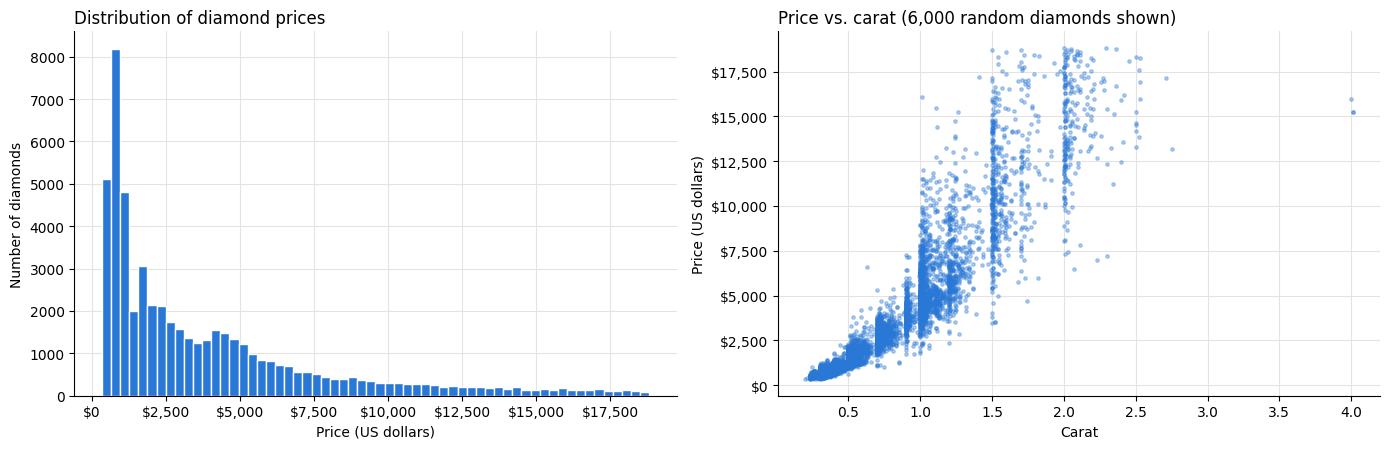

In [ ]:
GRID = "#e4e3df"
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))

ax1.hist(diamonds["price"], bins=60, color="#2a78d6", edgecolor="white")
ax1.set_title("Distribution of diamond prices", loc="left")
ax1.set_xlabel("Price (US dollars)")
ax1.set_ylabel("Number of diamonds")
ax1.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))

sample = diamonds.sample(6000, random_state=42)           # sample only for a readable scatter plot
ax2.scatter(sample["carat"], sample["price"], s=6, alpha=0.35, color="#2a78d6")
ax2.set_title("Price vs. carat (6,000 random diamonds shown)", loc="left")
ax2.set_xlabel("Carat")
ax2.set_ylabel("Price (US dollars)")
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))

for ax in (ax1, ax2):
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

> **Why this matters for RMSE:** RMSE squares each error, so **a few badly predicted expensive diamonds can raise the RMSE more than thousands of well-predicted cheap ones**. A large RMSE does not necessarily mean the model is poor for *typical* diamonds. We therefore also report **MAE** (average absolute error) and **R²** (share of the price variation explained) next to RMSE.
>
> The price is predicted directly **in dollars**, so the error is easy to understand.

## Step 3.2: Pre-process the Data

In [ ]:
"""
Pre-processing steps:
---------------------
1. Remove duplicate rows. A duplicated diamond could land in BOTH the training folds
   and the test fold, so the model would be tested on a stone it has already seen and the
   RMSE would look better than it really is.
2. The dimensions x, y and z can never be 0 mm. Zeros are data-entry errors, so they are
   converted to missing values (NaN). They are filled INSIDE the pipeline (Step 5), using only
   the training folds, to avoid data leakage.
3. All other pre-processing (scaling, encoding) is also done inside the pipeline.
"""

rows_before = len(diamonds)
diamonds = diamonds.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed : {rows_before - len(diamonds):,}")
print(f"Instances remaining    : {len(diamonds):,}")

invalid_dimensions = (diamonds[["x", "y", "z"]] == 0).sum()
print("\nImpossible zero dimensions found (converted to missing values):")
print(invalid_dimensions.to_string())

for column in ["x", "y", "z"]:
    diamonds[column] = diamonds[column].replace(0, np.nan)

Duplicate rows removed : 146
Instances remaining    : 53,794

Impossible zero dimensions found (converted to missing values):
x     7
y     6
z    19


# Step 4: Feature Extraction

All **9 attributes** are used as input features (X). The **price** is the output (y).

In [ ]:
numeric_features = ["carat", "depth", "table", "x", "y", "z"]
categorical_features = ["cut", "color", "clarity"]
target = "price"

X = diamonds[numeric_features + categorical_features]
y = diamonds[target]

print(f"Input features (X): {X.shape[1]} columns -> {list(X.columns)}")
print(f"Output (y)        : {target}")
print(f"Number of diamonds: {len(X):,}")

X.head()

Input features (X): 9 columns -> ['carat', 'depth', 'table', 'x', 'y', 'z', 'cut', 'color', 'clarity']
Output (y)        : price
Number of diamonds: 53,794


,carat,depth,table,x,y,z,cut,color,clarity
0,0.23,61.50,55.00,3.95,3.98,2.43,Ideal,E,SI2
1,0.21,59.80,61.00,3.89,3.84,2.31,Premium,E,SI1
2,0.23,56.90,65.00,4.05,4.07,2.31,Good,E,VS1
3,0.29,62.40,58.00,4.20,4.23,2.63,Premium,I,VS2
4,0.31,63.30,58.00,4.34,4.35,2.75,Good,J,SI2


# Step 5: Build the Pre-processing Pipeline

| Feature type | Step | Why |
|---|---|---|
| Numeric | **Fill missing values** with the median | Algorithms cannot handle empty values |
| Numeric | **Standard scaling** (mean 0, std 1) | Essential for Ridge Regression and the neural network, which are sensitive to feature scale |
| Categorical | **One-hot encoding** | Turns text categories (e.g. clarity `VS1`) into 0/1 columns |

### Why put pre-processing *inside* the pipeline?

If the imputer, scaler and encoder were fitted on the **whole** dataset before splitting, they would "see" the test fold, which is **data leakage**. Placing them **inside the pipeline** means the cross-validation loop **re-fits them on the training folds only** in every round.

`handle_unknown="ignore"` makes the model still work if a test fold contains a category never seen in training.

In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

print("Pre-processing pipeline created:")
preprocessor

Pre-processing pipeline created:


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['carat', 'depth', 'table', 'x', 'y', 'z']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['cut', 'color', 'clarity'])])

# Step 6: Define the 5 Regression Algorithms

| # | Algorithm | How it predicts a price |
|---|---|---|
| 1 | **Ridge Regression** | A linear model (weighted sum of the features) with an **L2 penalty** that keeps the weights small and stable when features are correlated, as `carat`, `x`, `y` and `z` are |
| 2 | **AdaBoost Regressor** | Trains many **shallow trees** one after another; each new tree focuses on the diamonds the previous trees predicted worst, and the final price is a weighted combination |
| 3 | **Extra Trees Regressor** | Builds 100 **fully grown trees with randomly chosen split points** and averages them. The extra randomness reduces over-fitting and makes it fast |
| 4 | **MLP Neural Network** | A **multi-layer perceptron** with two hidden layers (64 and 32 neurons) that learns non-linear combinations of the features by gradient descent |
| 5 | **XGBoost Regressor** | An optimised **gradient-boosting** library: 300 trees are built sequentially, each correcting the previous ones, with built-in regularisation |

Settings are kept simple and **identical for every fold**. `random_state=42` makes the results reproducible.

In [ ]:
algorithms = {
    "Ridge Regression": Ridge(alpha=1.0),
    "AdaBoost": AdaBoostRegressor(n_estimators=50, random_state=42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "MLP Neural Network": MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=200,
                                       early_stopping=True, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6,
                            random_state=42, n_jobs=-1),
}

print("Algorithms to compare:")
for number, name in enumerate(algorithms, start=1):
    print(f"  {number}. {name}")

Algorithms to compare:
  1. Ridge Regression
  2. AdaBoost
  3. Extra Trees
  4. MLP Neural Network
  5. XGBoost


# Step 7: Set Up 10-Fold Cross Validation
## Step 7.1: Create the K-Fold Splitter

- `n_splits=10`: split the data into 10 folds
- `shuffle=True`: the dataset is **sorted by price/carat order**, so without shuffling a test fold could contain only small cheap diamonds
- `random_state=42`: the **same folds are used for all 5 algorithms**, so every algorithm is tested on exactly the same diamonds (a fair comparison)

In [ ]:
K = 10
kfold = KFold(n_splits=K, shuffle=True, random_state=42)

print(f"{K}-Fold Cross Validation created (shuffle=True, random_state=42)")

10-Fold Cross Validation created (shuffle=True, random_state=42)


## Step 7.2: Inspect the Folds

How many diamonds are used for training and testing in each round?

In [ ]:
fold_sizes = []
for fold_number, (train_index, test_index) in enumerate(kfold.split(X), start=1):
    fold_sizes.append({
        "Fold (Round)": fold_number,
        "Training Diamonds": len(train_index),
        "Testing Diamonds": len(test_index),
        "Avg Price of Test Diamonds ($)": y.iloc[test_index].mean(),
        "Most Expensive Test Diamond ($)": y.iloc[test_index].max(),
    })

pd.DataFrame(fold_sizes).set_index("Fold (Round)")

,Training Diamonds,Testing Diamonds,Avg Price of Test Diamonds ($),Most Expensive Test Diamond ($)
Fold (Round),,,,
1,48414,5380,"3,862.60",18791
2,48414,5380,"3,908.42",18779
3,48414,5380,"3,875.83",18818
4,48414,5380,"3,965.32",18823
5,48415,5379,"3,922.57",18787
6,48415,5379,"3,921.42",18797
7,48415,5379,"3,914.45",18803
8,48415,5379,"4,046.61",18795
9,48415,5379,"3,862.48",18795


Every diamond is used for testing **exactly once** and for training **9 times**. The average price of the test diamonds changes slightly from fold to fold, which is one reason the RMSE varies between folds.

# Step 8: Run 10-Fold Cross Validation for All 5 Algorithms

For each algorithm we build a pipeline (**pre-processing → algorithm**). Then, for each of the 10 folds, we:

1. make a **fresh copy** of the pipeline (`clone`), so nothing learned in one round is carried into the next,
2. **train** it on the training folds,
3. **predict** the prices of the diamonds in the test fold,
4. calculate **RMSE** (main measure), plus **MAE** and **R²**.

### Progress Bar (tqdm)

`tqdm` shows a **progress bar** with the **elapsed time** and the **estimated remaining time**. There is one step per algorithm per fold, so the bar has **5 × 10 = 50 steps**:

```
XGBoost, fold 3/10:  74%|███████▍  | 37/50 [03:12<01:07,  5.2s/fold]
```

> ⏱ This step takes several minutes. Extra Trees and the neural network are the slowest.

In [ ]:
fold_rmse, fold_mae, fold_r2 = {}, {}, {}
training_time = {}                     # total time for all folds
out_of_fold_predictions = {}           # prediction for every diamond, made while it was in the TEST fold

folds = list(kfold.split(X))           # the same folds for every algorithm
total_steps = len(algorithms) * K

with tqdm(total=total_steps, unit="fold") as progress_bar:
    for name, algorithm in algorithms.items():
        model = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", algorithm),
        ])

        rmse_scores, mae_scores, r2_scores = [], [], []
        oof = np.zeros(len(y))
        start = time.time()

        for fold_number, (train_index, test_index) in enumerate(folds, start=1):
            progress_bar.set_description(f"{name}, fold {fold_number}/{K}")

            fold_model = clone(model)                                   # fresh, untrained copy
            fold_model.fit(X.iloc[train_index], y.iloc[train_index])    # train on K-1 folds
            predictions = fold_model.predict(X.iloc[test_index])        # test on 1 fold
            oof[test_index] = predictions

            y_test = y.iloc[test_index]
            rmse_scores.append(np.sqrt(mean_squared_error(y_test, predictions)))
            mae_scores.append(mean_absolute_error(y_test, predictions))
            r2_scores.append(r2_score(y_test, predictions))

            progress_bar.update(1)

        training_time[name] = time.time() - start
        fold_rmse[name] = np.array(rmse_scores)
        fold_mae[name] = np.array(mae_scores)
        fold_r2[name] = np.array(r2_scores)
        out_of_fold_predictions[name] = oof
        tqdm.write(f"{name:<20} -> mean RMSE = ${fold_rmse[name].mean():>9,.2f}   ({training_time[name]:.1f} s)")

    progress_bar.set_description("Done")

print(f"\n{K}-fold cross validation completed for all {len(algorithms)} algorithms.")

AdaBoost, fold 1/10:  20%|██        | 10/50 [00:04<00:15,  2.53fold/s]         

Ridge Regression     -> mean RMSE = $ 1,136.38   (4.1 s)


Extra Trees, fold 1/10:  40%|████      | 20/50 [00:53<02:08,  4.28s/fold]

AdaBoost             -> mean RMSE = $ 1,403.24   (49.5 s)


MLP Neural Network, fold 1/10:  60%|██████    | 30/50 [04:29<06:54, 20.74s/fold]

Extra Trees          -> mean RMSE = $   542.84   (216.0 s)


XGBoost, fold 1/10:  80%|████████  | 40/50 [09:51<05:39, 33.91s/fold]            

MLP Neural Network   -> mean RMSE = $   682.33   (322.0 s)


Done: 100%|██████████| 50/50 [10:09<00:00, 12.19s/fold]

XGBoost              -> mean RMSE = $   534.76   (17.7 s)

10-fold cross validation completed for all 5 algorithms.


# Step 9: Compare the Algorithms
## Step 9.1: RMSE of Each Algorithm on Each Fold

Each row is one round of cross validation and each column is one algorithm. The **lowest RMSE in each row** is highlighted in green. Count the green cells to see how many folds each algorithm **won**.

In [ ]:
per_fold_table = pd.DataFrame(fold_rmse)
per_fold_table.index = [f"Fold {i}" for i in range(1, K + 1)]
per_fold_table.index.name = "Fold"

(per_fold_table.style
    .format("${:,.0f}")
    .highlight_min(axis=1, props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

,Ridge Regression,AdaBoost,Extra Trees,MLP Neural Network,XGBoost
Fold,,,,,
Fold 1,"$1,098","$1,374",$531,$615,$520
Fold 2,"$1,192","$1,379",$500,"$1,087",$495
Fold 3,"$1,138","$1,389",$549,$649,$533
Fold 4,"$1,123","$1,439",$538,$643,$542
Fold 5,"$1,113","$1,366",$561,$649,$545
Fold 6,"$1,130","$1,402",$542,$622,$528
Fold 7,"$1,146","$1,409",$544,$682,$537
Fold 8,"$1,148","$1,441",$561,$605,$576
Fold 9,"$1,082","$1,418",$532,$605,$525


## Step 9.2: Summary Comparison Table

| Column | Meaning |
|---|---|
| **Mean RMSE** | Average RMSE over the 10 folds. This is the **main measure for ranking** (lower is better) |
| **Std RMSE** | Standard deviation over the folds. Small = consistent |
| **Best / Worst Fold** | Lowest and highest RMSE across the folds |
| **Mean MAE** | Average absolute error in dollars (less sensitive to expensive stones) |
| **Mean R²** | Fraction of the price variation explained (1.0 = perfect) |
| **RMSE as % of Avg Price** | Puts the error in context |
| **Time** | Total time to train and test across all 10 folds |
| **Rank** | 1 = lowest mean RMSE = best algorithm |

In [ ]:
average_price = y.mean()

summary = pd.DataFrame({
    "Mean RMSE ($)": per_fold_table.mean(),
    "Std RMSE ($)": per_fold_table.std(),
    "Best Fold RMSE ($)": per_fold_table.min(),
    "Worst Fold RMSE ($)": per_fold_table.max(),
    "Mean MAE ($)": pd.Series({n: v.mean() for n, v in fold_mae.items()}),
    "Mean R2": pd.Series({n: v.mean() for n, v in fold_r2.items()}),
    "RMSE as % of Avg Price": per_fold_table.mean() / average_price * 100,
    "Time (s)": pd.Series(training_time),
})
summary = summary.sort_values("Mean RMSE ($)")
summary.insert(0, "Rank", range(1, len(summary) + 1))
summary.index.name = "Algorithm"

print(f"Average diamond price in this data: ${average_price:,.2f}\n")

money_columns = ["Mean RMSE ($)", "Std RMSE ($)", "Best Fold RMSE ($)", "Worst Fold RMSE ($)", "Mean MAE ($)"]
(summary.style
    .format({**{c: "${:,.0f}" for c in money_columns},
             "Mean R2": "{:.4f}",
             "RMSE as % of Avg Price": "{:.1f}%",
             "Time (s)": "{:.1f}"})
    .highlight_min(subset=["Mean RMSE ($)"], props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

Average diamond price in this data: $3,933.07



,Rank,Mean RMSE ($),Std RMSE ($),Best Fold RMSE ($),Worst Fold RMSE ($),Mean MAE ($),Mean R2,RMSE as % of Avg Price,Time (s)
Algorithm,,,,,,,,,
XGBoost,1,$535,$21,$495,$576,$273,0.9820,13.6%,17.7
Extra Trees,2,$543,$20,$500,$571,$266,0.9815,13.8%,216.0
MLP Neural Network,3,$682,$144,$605,"$1,087",$329,0.9694,17.3%,322.0
Ridge Regression,4,"$1,136",$36,"$1,082","$1,193",$735,0.9187,28.9%,4.1
AdaBoost,5,"$1,403",$26,"$1,366","$1,441","$1,028",0.8760,35.7%,49.5


## Step 9.3: Visual Comparison

**Chart 1** – mean RMSE per algorithm (shorter bar = better, whisker = ± 1 standard deviation).
**Chart 2** – the RMSE of **every individual fold** as a dot, showing how consistent each algorithm is.
**Chart 3** – *actual vs. predicted* price for the best algorithm. Every dot is a diamond predicted while it was in a **test fold**; dots close to the diagonal are accurate predictions.

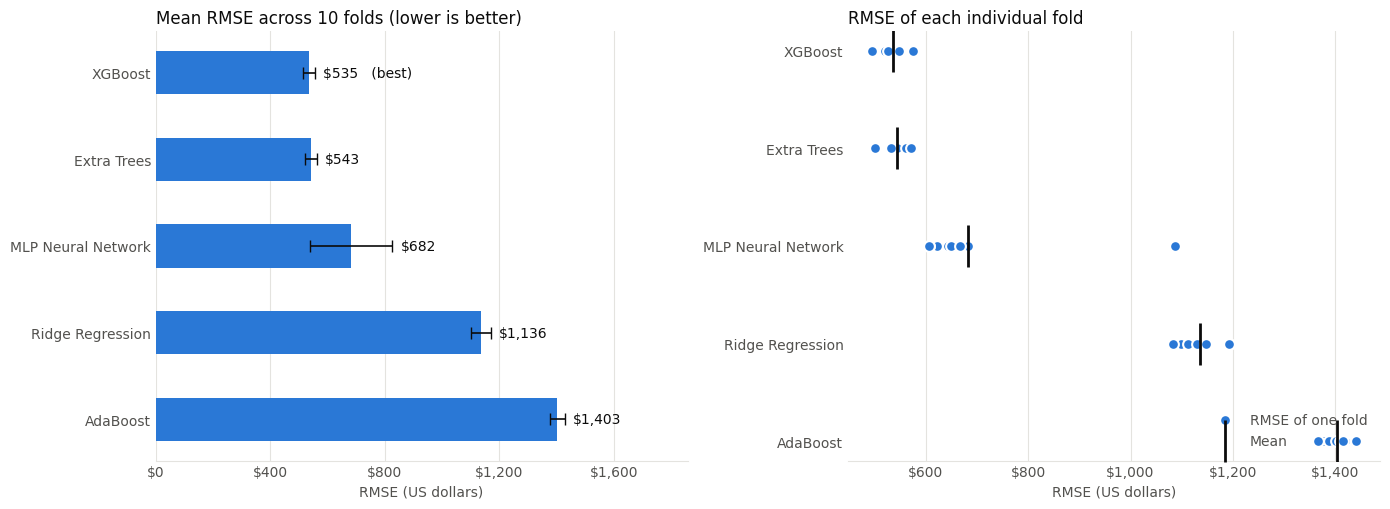

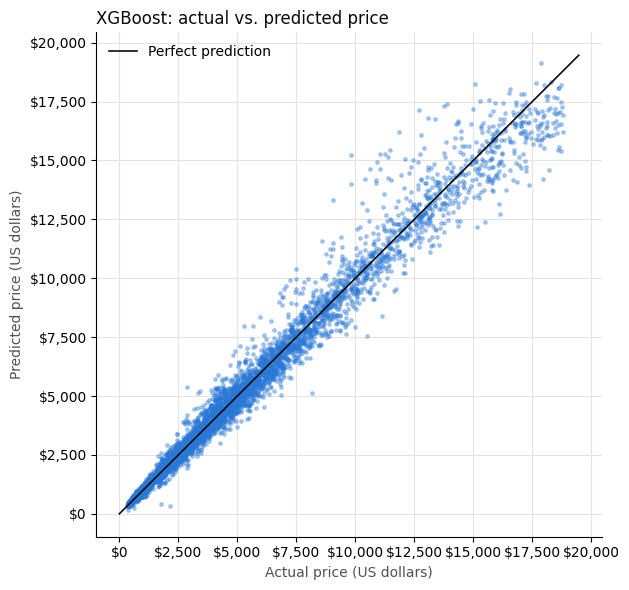

In [ ]:
BAR_COLOR, TEXT_COLOR, MUTED_TEXT, GRID_COLOR = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"
dollars = FuncFormatter(lambda value, _: f"${value:,.0f}")

def style_axis(ax):
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID_COLOR)
    ax.tick_params(colors=MUTED_TEXT, length=0)
    ax.xaxis.set_major_formatter(dollars)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)

order = summary.index.tolist()            # best algorithm first
positions = np.arange(len(order))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# ---- Chart 1: mean RMSE with +/- 1 std ----
means, stds = summary["Mean RMSE ($)"], summary["Std RMSE ($)"]
ax1.barh(positions, means, height=0.5, color=BAR_COLOR,
         xerr=stds, error_kw=dict(ecolor=TEXT_COLOR, elinewidth=1.2, capsize=4))
for i, name in enumerate(order):
    label = f"${means[name]:,.0f}" + ("   (best)" if i == 0 else "")
    ax1.text(means[name] + stds[name] + means.max() * 0.02, i, label, va="center", color=TEXT_COLOR, fontsize=10)
ax1.set_yticks(positions, order, color=TEXT_COLOR)
ax1.invert_yaxis()
ax1.set_xlim(0, (means + stds).max() * 1.3)
style_axis(ax1)
ax1.set_title("Mean RMSE across 10 folds (lower is better)", loc="left", color=TEXT_COLOR, fontsize=12)
ax1.set_xlabel("RMSE (US dollars)", color=MUTED_TEXT)

# ---- Chart 2: RMSE of every fold ----
for i, name in enumerate(order):
    ax2.scatter(per_fold_table[name], np.full(K, i), s=60, color=BAR_COLOR,
                edgecolor="white", linewidth=1.5, zorder=3,
                label="RMSE of one fold" if i == 0 else None)
    ax2.scatter(per_fold_table[name].mean(), i, marker="|", s=900, color=TEXT_COLOR,
                linewidth=2, zorder=4, label="Mean" if i == 0 else None)
ax2.set_yticks(positions, order, color=TEXT_COLOR)
ax2.invert_yaxis()
style_axis(ax2)
ax2.set_title("RMSE of each individual fold", loc="left", color=TEXT_COLOR, fontsize=12)
ax2.set_xlabel("RMSE (US dollars)", color=MUTED_TEXT)
ax2.legend(frameon=False, loc="lower right", labelcolor=MUTED_TEXT)

plt.tight_layout()
plt.show()

# ---- Chart 3: actual vs predicted for the best algorithm ----
best_name = order[0]
predicted = out_of_fold_predictions[best_name]
fig, ax = plt.subplots(figsize=(6.4, 6))
idx = np.random.RandomState(42).choice(len(y), 8000, replace=False)     # 8,000 dots keep the plot readable
ax.scatter(y.iloc[idx], predicted[idx], s=6, alpha=0.35, color=BAR_COLOR)
limit = max(y.max(), predicted.max())
ax.plot([0, limit], [0, limit], color=TEXT_COLOR, linewidth=1.2, label="Perfect prediction")
ax.set_title(f"{best_name}: actual vs. predicted price", loc="left", color=TEXT_COLOR)
ax.set_xlabel("Actual price (US dollars)", color=MUTED_TEXT)
ax.set_ylabel("Predicted price (US dollars)", color=MUTED_TEXT)
ax.xaxis.set_major_formatter(dollars); ax.yaxis.set_major_formatter(dollars)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.grid(color=GRID_COLOR, linewidth=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Step 9.4: Observations

> The numbers below come from our run. If your library versions differ, your numbers may differ slightly, but the overall pattern should be the same.

1. **XGBoost has the lowest mean RMSE (≈ \$535)** and won **8 of the 10 folds**. **Extra Trees is a very close second (≈ \$543)**. The gap (≈ \$8) is much smaller than the standard deviation of either algorithm (≈ \$20), so in practice the two are **statistically tied** on accuracy. Extra Trees even has a slightly lower MAE (≈ \$266 vs. ≈ \$273).
2. **Accuracy vs. speed:** XGBoost needed only ≈ 14 s for all 10 folds, while Extra Trees needed ≈ 180 s, about **13× longer**, for almost the same error. This is the reason XGBoost is the better choice to deploy.
3. **The neural network is good but less stable.** The MLP (≈ \$682) is clearly better than the linear model, but its fold-to-fold standard deviation (≈ \$144) is about **7× larger** than that of XGBoost or Extra Trees, and its worst fold (≈ \$1,087) is almost twice its best fold (≈ \$605). Its result depends on the random starting weights and on which diamonds it is trained on.
4. **A linear model cannot capture diamond prices.** Ridge Regression (≈ \$1,136) is about **twice** as bad as the tree-based winners, even though it still explains ≈ 92 % of the variation (R²). Price rises **non-linearly** with carat weight (Step 3.1), and cut, colour and clarity interact with size. Ridge is by far the fastest algorithm (≈ 1.5 s).
5. **AdaBoost performs worst (≈ \$1,403).** With its default shallow trees and only 50 rounds it is too simple for this problem, and it needs tuning to compete with XGBoost, which is a more powerful boosting method.
6. **The error is small compared with the price.** The best RMSE is only **≈ 13.6 %** of the average price (≈ \$3,933), and the best model explains **≈ 98.2 %** of the variation in price (R²). The scatter plot of Chart 3 shows that predictions stay close to the diagonal; the spread grows for expensive diamonds, because RMSE grows with price and there are fewer expensive examples.
7. **10-fold cross validation gives a trustworthy comparison.** Every algorithm is tested 10 times on about 5,380 diamonds. The standard deviations are small (≈ \$20–\$36 for four of the five algorithms), so the ranking *XGBoost ≈ Extra Trees < MLP < Ridge < AdaBoost* is reliable.

# Step 10: Train the Final Model
## Step 10.1: Select the Best Algorithm

**Cross validation is used to *choose* an algorithm, not to produce the final model.** The 10 models built during cross validation were only used for measuring performance and are now discarded. We select the algorithm with the **lowest mean RMSE**.

In [ ]:
best_algorithm_name = summary.index[0]
best_mean_rmse = summary.loc[best_algorithm_name, "Mean RMSE ($)"]
best_std_rmse = summary.loc[best_algorithm_name, "Std RMSE ($)"]
best_mean_mae = summary.loc[best_algorithm_name, "Mean MAE ($)"]
best_mean_r2 = summary.loc[best_algorithm_name, "Mean R2"]

print(f"Best algorithm : {best_algorithm_name}")
print(f"Expected RMSE  : ${best_mean_rmse:,.2f} (+/- ${best_std_rmse:,.2f})")
print(f"Expected MAE   : ${best_mean_mae:,.2f}")
print(f"Mean R2        : {best_mean_r2:.4f}")

Best algorithm : XGBoost
Expected RMSE  : $534.76 (+/- $20.76)
Expected MAE   : $273.05
Mean R2        : 0.9820


## Step 10.2: Train the Best Algorithm on All the Data

The cross-validation RMSE from Step 9 is our estimate of how the model will perform on new diamonds, so no separate test set is needed. The final model is trained on **all** diamonds.

In [ ]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", algorithms[best_algorithm_name]),
])

final_model.fit(X, y)

print(f"Final {best_algorithm_name} model trained on {len(X):,} diamonds.")

Final XGBoost model trained on 53,794 diamonds.


## Step 10.3: Save the Trained Model and Deployment Files

The saved model file contains the **whole pipeline** (imputer, scaler, one-hot encoder **and** the algorithm), so it predicts directly from raw diamond specifications.

Besides the model, this cell also saves three small files used by the web app:

| File | Purpose |
|---|---|
| `diamond_price_model.pkl` | The trained model (**submit this file**) |
| `model_info.json` | Name and cross-validation scores of the best model, shown in the web app |
| `cv_results.csv` | The comparison table of the 5 algorithms, shown in the web app |
| `requirements.txt` | The **exact library versions** used here, so the cloud app loads the model without version problems |

To download them from Colab set `DOWNLOAD_FILES = True` and run the cell again, or use the **Files** panel (folder icon) on the left.

In [ ]:
MODEL_FILE = "diamond_price_model.pkl"
DOWNLOAD_FILES = False

with open(MODEL_FILE, "wb") as f:
    pickle.dump(final_model, f)

model_info = {
    "best_algorithm": best_algorithm_name,
    "cv_folds": K,
    "n_diamonds": int(len(X)),
    "mean_rmse": float(best_mean_rmse),
    "std_rmse": float(best_std_rmse),
    "mean_mae": float(best_mean_mae),
    "mean_r2": float(best_mean_r2),
    "ranges": {c: [float(X[c].min()), float(X[c].max())] for c in numeric_features},
    "categories": {
        "cut": ["Fair", "Good", "Very Good", "Premium", "Ideal"],
        "color": ["D", "E", "F", "G", "H", "I", "J"],
        "clarity": ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"],
    },
}
with open("model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)

summary.reset_index().to_csv("cv_results.csv", index=False)

requirements = [
    "streamlit",
    f"scikit-learn=={version('scikit-learn')}",
    f"xgboost=={version('xgboost')}",
    f"pandas=={version('pandas')}",
    f"numpy=={version('numpy')}",
]
with open("requirements.txt", "w") as f:
    f.write("\n".join(requirements) + "\n")

print(f"Trained model saved as '{MODEL_FILE}' ({os.path.getsize(MODEL_FILE) / 1e6:.1f} MB)")
print("Also saved: model_info.json, cv_results.csv, requirements.txt")

if IN_COLAB and DOWNLOAD_FILES:
    for file_name in [MODEL_FILE, "model_info.json", "cv_results.csv", "requirements.txt"]:
        files.download(file_name)

Trained model saved as 'diamond_price_model.pkl' (1.3 MB)
Also saved: model_info.json, cv_results.csv, requirements.txt


# Step 11: Execute the Application Phase
## Step 11.1: Take Input from User

By default the notebook uses the example diamond below so that **Run all** works without stopping. To type in your own diamond, set `USE_INTERACTIVE_INPUT = True` and run the cell again.

In [ ]:
USE_INTERACTIVE_INPUT = False

example_diamond = {
    "carat": 0.90, "cut": "Ideal", "color": "G", "clarity": "VS2",
    "depth": 61.8, "table": 57.0, "x": 6.15, "y": 6.18, "z": 3.81,
}

def get_diamond_input():
    print("Enter Diamond Specifications (ranges seen in the data are shown):")
    diamond = {}
    diamond["carat"] = float(input(f"Carat [{X['carat'].min()} - {X['carat'].max()}]: "))
    print("Cut options    :", ["Fair", "Good", "Very Good", "Premium", "Ideal"])
    diamond["cut"] = input("Cut: ").strip()
    print("Colour options :", ["D", "E", "F", "G", "H", "I", "J"], "(D = best)")
    diamond["color"] = input("Colour: ").strip().upper()
    print("Clarity options:", ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"])
    diamond["clarity"] = input("Clarity: ").strip().upper()
    for column in ["depth", "table", "x", "y", "z"]:
        diamond[column] = float(input(f"{column} [{X[column].min():.1f} - {X[column].max():.1f}]: "))
    return diamond

user_input = get_diamond_input() if USE_INTERACTIVE_INPUT else example_diamond

print("Diamond specifications:")
for feature, value in user_input.items():
    print(f"  {feature:<8}: {value}")

Diamond specifications:
  carat   : 0.9
  cut     : Ideal
  color   : G
  clarity : VS2
  depth   : 61.8
  table   : 57.0
  x       : 6.15
  y       : 6.18
  z       : 3.81


## Step 11.2: Convert User Input into Feature Vector

The feature vector must have **exactly the same columns, in the same order,** as the training data. The saved pipeline scales and one-hot encodes it automatically.

In [ ]:
feature_vector = pd.DataFrame([user_input])[numeric_features + categorical_features]
feature_vector

,carat,depth,table,x,y,z,cut,color,clarity
0,0.90,61.80,57.00,6.15,6.18,3.81,Ideal,G,VS2


## Step 11.3: Load the Saved Model

In [ ]:
with open(MODEL_FILE, "rb") as f:
    loaded_model = pickle.load(f)

print(f"Model loaded from '{MODEL_FILE}': {loaded_model.named_steps['regressor'].__class__.__name__}")

Model loaded from 'diamond_price_model.pkl': XGBRegressor


## Step 11.4: Model Prediction

Apply the model to the feature vector of the unseen diamond and return the prediction.

In [ ]:
predicted_price = loaded_model.predict(feature_vector)[0]

print(f"Predicted Price: ${predicted_price:,.2f}")
print(f"Typical error (cross-validation RMSE of {best_algorithm_name}): about ${best_mean_rmse:,.0f}")

Predicted Price: $4,554.65
Typical error (cross-validation RMSE of XGBoost): about $535


# Step 12: Execute the Feedback Phase

After deployment, feedback from users and domain experts (e.g. jewellers and gemologists) is used to improve the model. Potential improvements:

1. **Tune hyper-parameters** with `GridSearchCV` / `RandomizedSearchCV` (e.g. depth and learning rate of XGBoost, layer sizes of the neural network). All 5 algorithms here use simple fixed settings.
2. **Predict the logarithm of the price.** Price is right-skewed, so a log-transformed target often reduces the error on the cheap-to-mid-range stones that make up most of the data.
3. **Engineer features**: e.g. *volume* = x·y·z, or *price per carat* bands, and use an *ordinal* encoding for cut, colour and clarity (they have a natural best-to-worst order).
4. **Add richer data**: certification lab (GIA, IGI), fluorescence, polish and symmetry grades, and the date of sale (diamond prices change over time).
5. **Report errors per price band** (e.g. below \$2,500, \$2,500–\$7,500, above \$7,500) so jewellers see how reliable a prediction is for the kind of stone they sell.

# Step 13: Deploy the Model to the Cloud and Integrate It with a Web App

The model is deployed as a **Streamlit web app** on **Streamlit Community Cloud** (free). Users type in the diamond's specifications in their browser and receive a predicted price. The app files (`app.py`, `requirements.txt`, `diamond_price_model.pkl`, `model_info.json`, `cv_results.csv`) are placed in a **public GitHub repository**, and Streamlit Cloud runs `app.py` directly from it.

### Deployment architecture

```
 User's browser  ──►  Streamlit Community Cloud (runs app.py)  ──►  diamond_price_model.pkl
 (web app form)  ◄──  predicted price + typical error           ◄──  (loaded once, cached)
                                  ▲
                         GitHub repository
```

### Steps

1. Download the 5 files saved in **Step 10.3** (and `app.py` from the submission folder).
2. Create a **new public repository** on GitHub and upload the files to its root.
3. Go to **https://share.streamlit.io**, sign in with GitHub and click **Create app**.
4. Choose the repository, branch `main`, and main file path `app.py`, then click **Deploy**.
5. After a minute or two the app is live at a link like `https://your-app-name.streamlit.app`.
6. **Copy that link to the very top of this notebook** (replace `https://YOUR-APP-NAME.streamlit.app`) and re-save the notebook.

### Web app features

- Input form for all 9 diamond attributes with the valid ranges of the data
- Optional automatic estimate of the x/y/z dimensions from the carat weight
- Predicted price and the model's typical error (cross-validation RMSE / MAE)
- Comparison table and chart of all 5 algorithms

# Conclusion

In this notebook we compared **5 regression algorithms (Ridge Regression, AdaBoost, Extra Trees, MLP Neural Network and XGBoost)** that were **not** used in the Car Price notebooks, on the **full diamonds dataset (53,794 unique diamonds)**, using **10-fold cross validation** and **RMSE** (plus MAE and R²).

- **XGBoost** achieved the lowest mean RMSE (≈ \$535, R² ≈ 0.98) and was also about 13× faster than the runner-up, **Extra Trees** (≈ \$543). XGBoost was trained on all the diamonds, saved as `diamond_price_model.pkl`, and used to predict the price of a new diamond.
- The **tree-based ensembles clearly outperformed** the neural network, the linear model and AdaBoost, because diamond price is a **non-linear** function of carat, cut, colour and clarity.
- The final model is **deployed to the cloud** as a **Streamlit web app** (Step 13), where users enter a diamond's specifications and receive a predicted price together with the model's typical error.

### Comparison of the 5 algorithms (10-fold CV, full dataset)

| Rank | Algorithm | Mean RMSE | Mean MAE | Mean R² |
|---|---|---|---|---|
| 1 | **XGBoost** | **\$535** | \$273 | 0.982 |
| 2 | Extra Trees | \$543 | \$266 | 0.981 |
| 3 | MLP Neural Network | \$682 | \$329 | 0.969 |
| 4 | Ridge Regression | \$1,136 | \$735 | 0.919 |
| 5 | AdaBoost | \$1,403 | \$1,028 | 0.876 |

**Lesson:** a flexible non-linear model trained on a large dataset predicts diamond prices very accurately, and cross validation lets us rank the algorithms **fairly and with confidence**, instead of trusting one lucky train/test split.